# Stage 4: Main model: comparison, calibration, interpretation

`05_lightgbm.ipynb` showed that the model class and tuning change little, and that play-by-play context features help.
This notebook:
1. compares the logit and LightGBM **with the same information** (both with and without context),
2. checks the calibration of the candidates and whether isotonic recalibration helps,
3. interprets the main model with SHAP values.

Validation as before: walk-forward by season, test seasons 2015-16 to 2024-25, hold-out 2025-26 never loaded.
The out-of-sample predictions are saved to `data/processed/oos_predictions.parquet` for Stage 5 (player xPTS).

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression

from xpts.baselines import make_logit
from xpts.gbm import CONTEXT_FEATURES, GBM_FEATURES, GBMModel, gbm_matrix
from xpts.metrics import calibration_table, evaluate, paired_bootstrap
from xpts.validation import HOLDOUT_SEASON, walk_forward

FIG_DIR = Path("../reports/figures")
KEY = ["GAME_ID", "GAME_EVENT_ID"]

df = pd.read_parquet("../data/processed/shots_features.parquet")
df = df[df["SEASON"] != HOLDOUT_SEASON].reset_index(drop=True)  # hold-out season, never used here
df = df.merge(pd.read_parquet("../data/processed/shots_context.parquet"), on=KEY, how="left", validate="1:1")
y = df["SHOT_MADE_FLAG"]
print(f"shots: {len(df):,}, seasons: {df['SEASON'].min()} to {df['SEASON'].max()}, "
      f"with context: {df['prev_event'].notna().mean():.4f}")

shots: 2,305,805, seasons: 2014-15 to 2024-25, with context: 0.9997


## 1. Same information for both models

**Why.** In `05_lightgbm` the LightGBM with context was compared with a logit without it. To separate the effect of the
*model* from the effect of the *information*, the logit gets the same four features (`ContextFeatures` in
`src/xpts/baselines.py`): B-splines of `secs_since_prev` with a separate curve for every `prev_event` (the same
construction as distance x shot type), `score_margin` (and its absolute value) and `is_home`.

Each model keeps its best training window from the earlier experiments: 1 season for the logit, 2 for LightGBM
(with context the logit on 2 seasons gives the same mean log loss, 0.6391 vs 0.6390).

In [2]:
models = {
    "logit_w1": (lambda: make_logit(), 1),
    "logit_w1_ctx": (lambda: make_logit(context=True), 1),
    "gbm_w2": (lambda: GBMModel(), 2),
    "gbm_w2_ctx": (lambda: GBMModel(features=GBM_FEATURES + CONTEXT_FEATURES), 2),
}
oos = df[KEY + ["SEASON"]].assign(y=y)
rows = []
for name, (make, window) in models.items():
    for season, tr, te in walk_forward(df["SEASON"], window=window):
        p = make().fit(df[tr], y[tr]).predict_proba(df[te])[:, 1]
        oos.loc[te, name] = p
        rows.append({"model": name, "season": season, **evaluate(y[te], p)})

results = pd.DataFrame(rows)
oos = oos.dropna(subset=["logit_w1"])  # 2014-15 is only a training season
oos.to_parquet("../data/processed/oos_predictions.parquet")
display(results.groupby("model")[["log_loss", "brier", "auc"]].mean().loc[list(models)].round(4))
display(results.pivot(index="season", columns="model", values="log_loss")[list(models)].round(4))

,log_loss,brier,auc
model,,,
logit_w1,0.6402,0.2255,0.6562
logit_w1_ctx,0.6390,0.2250,0.6583
gbm_w2,0.6412,0.2260,0.6541
gbm_w2_ctx,0.6390,0.2251,0.6580


model,logit_w1,logit_w1_ctx,gbm_w2,gbm_w2_ctx
season,,,,
2015-16,0.6367,0.6333,0.6368,0.6323
2016-17,0.6386,0.6355,0.6379,0.6340
2017-18,0.6478,0.6483,0.6586,0.6539
2018-19,0.6372,0.6358,0.6378,0.6359
2019-20,0.6367,0.6359,0.6360,0.6357
2020-21,0.6446,0.6436,0.6454,0.6433
2021-22,0.6395,0.6385,0.6396,0.6379
2022-23,0.6401,0.6393,0.6398,0.6385
2023-24,0.6406,0.6400,0.6402,0.6391


In [3]:
after = oos["SEASON"] >= "2018-19"  # seasons after the ACTION_TYPE label change
pairs = [("logit_w1_ctx", "logit_w1"), ("gbm_w2_ctx", "gbm_w2"), ("gbm_w2", "logit_w1"), ("gbm_w2_ctx", "logit_w1_ctx")]
ci = pd.DataFrame({(f"{a} - {b}", period): paired_bootstrap(oos.loc[m, "y"], oos.loc[m, a], oos.loc[m, b], oos.loc[m, "GAME_ID"])
                   for a, b in pairs
                   for period, m in [("all", oos["y"].notna()), ("2018-19+", after)]}).T
display(ci.round(5))
ci_s = pd.DataFrame({s: paired_bootstrap(g["y"], g["gbm_w2_ctx"], g["logit_w1_ctx"], g["GAME_ID"])
                     for s, g in oos.groupby("SEASON")}).T
display(ci_s.round(5))

diff   ci_low  ci_high  share_a_better
logit_w1_ctx - logit_w1   all      -0.00121 -0.00130 -0.00113           1.000
                          2018-19+ -0.00089 -0.00098 -0.00081           1.000
gbm_w2_ctx - gbm_w2       all      -0.00226 -0.00236 -0.00216           1.000
                          2018-19+ -0.00136 -0.00147 -0.00126           1.000
gbm_w2 - logit_w1         all       0.00099  0.00087  0.00111           0.000
                          2018-19+ -0.00005 -0.00015  0.00005           0.825
gbm_w2_ctx - logit_w1_ctx all      -0.00006 -0.00017  0.00006           0.838
                          2018-19+ -0.00052 -0.00063 -0.00040           1.000

,diff,ci_low,ci_high,share_a_better
2015-16,-0.00099,-0.00137,-0.00061,1.000
2016-17,-0.00157,-0.00193,-0.00123,1.000
2017-18,0.00560,0.00506,0.00611,0.000
2018-19,0.00016,-0.00021,0.00053,0.189
2019-20,-0.00026,-0.00066,0.00013,0.909
2020-21,-0.00030,-0.00063,0.00002,0.963
2021-22,-0.00053,-0.00081,-0.00023,1.000
2022-23,-0.00073,-0.00099,-0.00046,1.000
2023-24,-0.00094,-0.00122,-0.00066,1.000
2024-25,-0.00100,-0.00125,-0.00073,1.000


**Observations.**
- **Information matters, the model class much less.** Context improves both models: logit −0.0012 [−0.0013; −0.0011],
  LightGBM −0.0023 [−0.0024; −0.0022]. With the same features the two are tied over the 10 seasons:
  0.6390 vs 0.6390, difference −0.00006 [−0.00017; 0.00006].
- The tie hides two periods. In 2017-18 (label change) the logit is clearly better (+0.0056 for LightGBM): the trees split
  on label patterns that disappear, the logit degrades more gracefully. After 2018-19 LightGBM is better by
  −0.0005 [−0.0006; −0.0004], and in each of the last four seasons (2021-22 to 2024-25) the whole CI is below zero
  (−0.0005 to −0.0010).
- **Main model: `gbm_w2_ctx`** (LightGBM, 2-season window, default parameters, shot + context features). It is the best
  model in the recent seasons, which are the ones used in the player analysis and the simulation. Its weakness is the
  sensitivity to a change of the label vocabulary; the logit with context stays as the reference model.
- Honest size of the effect: from the null model (0.6905) the zone baseline gains 0.030, the spline logit another 0.021,
  context 0.0012, and the switch to LightGBM 0.0005 in recent seasons. Most of what is predictable is in *where and how*
  the shot was taken.

## 2. Calibration

**Why it matters.** xPTS (Stage 5) and the Monte Carlo simulation (Stage 6) use the predicted probabilities directly, so
a model that ranks shots well but is shifted (e.g. predicts 50% where 47% go in) would bias every player's result.

**Checks**, all on out-of-sample predictions:
- calibration curve in 20 quantile bins (predicted vs observed FG%),
- **ECE** (expected calibration error): mean |observed − predicted| over the bins, weighted by bin size,
- bias per season (observed FG% − mean prediction),
- bias in subgroups (shot type, 2PT / 3PT), because a model can be calibrated on average and wrong in parts.

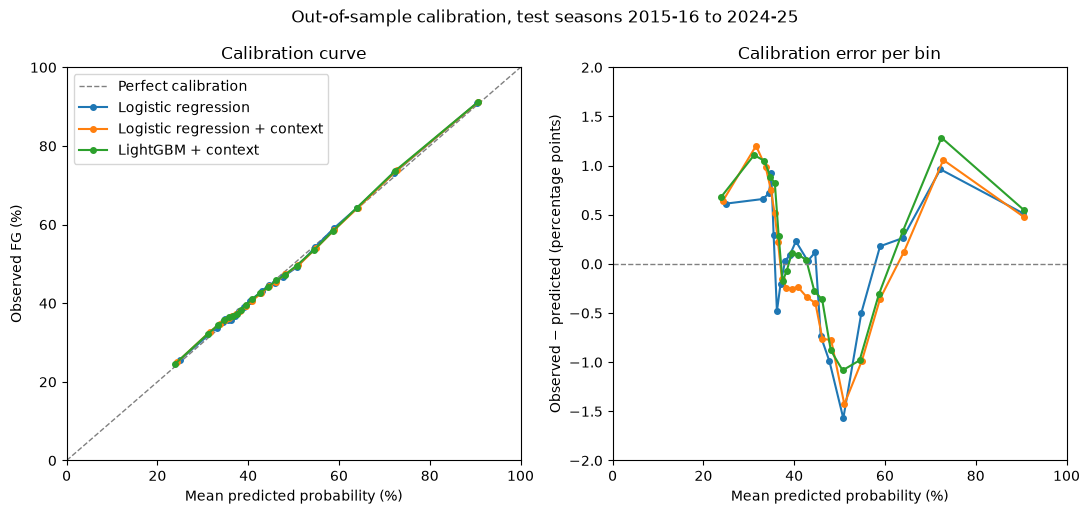

,ECE,bias
logit_w1,0.0051,0.0006
logit_w1_ctx,0.0059,0.0000
gbm_w2,0.0070,0.0025
gbm_w2_ctx,0.0057,0.0015


,logit_w1,logit_w1_ctx,gbm_w2,gbm_w2_ctx
SEASON,,,,
2015-16,-0.012,-0.012,-0.010,-0.011
2016-17,0.001,0.001,-0.003,-0.004
2017-18,-0.003,-0.007,0.011,0.006
2018-19,-0.006,-0.007,-0.007,-0.009
2019-20,0.004,0.004,0.001,0.000
2020-21,0.016,0.016,0.014,0.015
2021-22,-0.002,-0.002,0.005,0.005
2022-23,0.011,0.010,0.010,0.009
2023-24,0.001,0.001,0.007,0.006


In [4]:
def ece(y_true, p, n_bins=20):
    """Expected calibration error on quantile bins."""
    cal = calibration_table(y_true, p, n_bins)
    return float((cal["n"] * (cal["y_mean"] - cal["p_mean"]).abs()).sum() / cal["n"].sum())


labels = {"logit_w1": "Logistic regression", "logit_w1_ctx": "Logistic regression + context",
          "gbm_w2_ctx": "LightGBM + context"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
axes[0].plot([0, 100], [0, 100], color="grey", ls="--", lw=1, label="Perfect calibration")
for m, label in labels.items():
    cal = calibration_table(oos["y"], oos[m])
    axes[0].plot(100 * cal["p_mean"], 100 * cal["y_mean"], marker="o", ms=4, label=label)
    axes[1].plot(100 * cal["p_mean"], 100 * (cal["y_mean"] - cal["p_mean"]), marker="o", ms=4, label=label)
axes[0].set(xlabel="Mean predicted probability (%)", ylabel="Observed FG (%)", xlim=(0, 100), ylim=(0, 100), title="Calibration curve")
axes[0].legend()
axes[1].axhline(0, color="grey", ls="--", lw=1)
axes[1].set(xlabel="Mean predicted probability (%)", ylabel="Observed − predicted (percentage points)", xlim=(0, 100), ylim=(-2, 2),
            title="Calibration error per bin")
fig.suptitle("Out-of-sample calibration, test seasons 2015-16 to 2024-25")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_calibration_main.pdf")
plt.show()

display(pd.DataFrame({m: {"ECE": ece(oos["y"], oos[m]), "bias": oos["y"].mean() - oos[m].mean()} for m in models}).T.round(4))
bias = oos.groupby("SEASON")[list(models)].mean().rsub(oos.groupby("SEASON")["y"].mean(), axis=0)
display(bias.round(3))

In [5]:
# bias in subgroups for the two context models: observed FG% − mean prediction
sub = oos.join(df[["action_group", "is_three", "prev_event"]])
for col in ["action_group", "is_three", "prev_event"]:
    g = sub.groupby(col, observed=True)
    t = pd.DataFrame({"n": g.size(), "fg_pct": g["y"].mean(),
                      "bias_logit_ctx": g["y"].mean() - g["logit_w1_ctx"].mean(),
                      "bias_gbm_ctx": g["y"].mean() - g["gbm_w2_ctx"].mean()})
    display(t.sort_values("n", ascending=False).round(3))

,n,fg_pct,bias_logit_ctx,bias_gbm_ctx
action_group,,,,
jumper,785922,0.356,0.001,0.003
layup,488361,0.559,0.008,0.017
pullup_jumper,236493,0.417,-0.015,-0.022
floater,147824,0.452,-0.007,-0.010
dunk,117899,0.894,0.012,0.015
fadeaway_jumper,96240,0.427,-0.007,-0.009
stepback_jumper,83983,0.401,-0.010,-0.013
tip_putback,73217,0.561,0.002,-0.002
hook,68420,0.482,-0.003,-0.006


,n,fg_pct,bias_logit_ctx,bias_gbm_ctx
is_three,,,,
0,1328270,0.524,0.001,0.003
1,771985,0.359,-0.001,-0.001


,n,fg_pct,bias_logit_ctx,bias_gbm_ctx
prev_event,,,,
made_shot,609730,0.446,-0.001,0.001
def_rebound,607725,0.465,-0.000,0.002
off_rebound,224856,0.500,0.002,0.001
free_throw,167110,0.439,0.001,0.002
steal,130970,0.568,0.003,0.006
dead_turnover,104983,0.442,0.001,0.003
foul,104605,0.434,-0.003,-0.001
timeout,86688,0.430,0.000,0.001
period_start,26873,0.437,0.002,0.005


In [6]:
# what is inside each of the 20 calibration bins of the main model (right panel of the figure)
b = oos[["y", "gbm_w2_ctx"]].join(df[["dist_ft", "is_three", "action_group"]])
b["bin"] = pd.qcut(b["gbm_w2_ctx"], 20, labels=False)
b["action_group"] = b["action_group"].astype(str)
g = b.groupby("bin")
bins = pd.DataFrame({"pred_pct": 100 * g["gbm_w2_ctx"].mean(), "error_pp": 100 * (g["y"].mean() - g["gbm_w2_ctx"].mean()),
                     "share_3pt": g["is_three"].mean(), "median_dist_ft": g["dist_ft"].median(),
                     "top_types": g["action_group"].agg(lambda s: ", ".join(f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(3).items()))})
display(bins.round(2))
# error of the main model by season in ranges of the prediction (percentage points)
b["range"] = pd.cut(b["gbm_w2_ctx"], [0, 0.38, 0.44, 0.56, 0.8, 1])
display((100 * (b["y"] - b["gbm_w2_ctx"])).groupby([oos["SEASON"], b["range"]], observed=True).mean().unstack().round(1))


,pred_pct,error_pp,share_3pt,median_dist_ft,top_types
bin,,,,,
0,23.84,0.68,0.47,19.33,"jumper 68%, layup 18%, pullup_jumper 8%"
1,31.17,1.11,0.63,25.04,"jumper 73%, layup 15%, pullup_jumper 6%"
2,33.46,1.05,0.76,25.41,"jumper 81%, layup 8%, pullup_jumper 6%"
3,34.77,0.88,0.79,25.38,"jumper 83%, pullup_jumper 6%, layup 6%"
4,35.74,0.82,0.79,25.27,"jumper 82%, pullup_jumper 7%, layup 5%"
5,36.59,0.28,0.78,25.11,"jumper 80%, pullup_jumper 9%, layup 5%"
6,37.44,-0.18,0.75,24.82,"jumper 75%, pullup_jumper 11%, layup 6%"
7,38.37,-0.07,0.71,23.98,"jumper 69%, pullup_jumper 13%, layup 7%"
8,39.50,0.11,0.64,23.08,"jumper 61%, pullup_jumper 13%, layup 10%"


range,"(0.0, 0.38]","(0.38, 0.44]","(0.44, 0.56]","(0.56, 0.8]","(0.8, 1.0]"
SEASON,,,,,
2015-16,-0.8,-1.0,-0.7,-2.7,0.6
2016-17,-0.2,0.3,-0.5,-1.1,0.2
2017-18,2.9,2.2,-3.9,2.4,6.1
2018-19,-0.2,-1.8,-2.8,1.3,1.4
2019-20,0.3,-0.7,0.3,0.1,0.3
2020-21,2.1,1.1,1.9,0.5,-0.2
2021-22,0.4,-0.1,0.5,1.8,0.2
2022-23,0.6,0.6,1.1,2.1,0.4
2023-24,1.1,0.3,0.4,0.5,0.3


### 2b. Isotonic recalibration

**Idea.** Isotonic regression learns a monotone map from the predicted probability to the observed frequency and can
repair a systematic distortion of the curve. To keep it honest the map for test season S is fitted only on the
out-of-sample predictions of season S-1 (which the model for S-1 never saw in training), so no test season calibrates
itself. The first test season has no earlier predictions, so the comparison covers 2016-17 to 2024-25.

In [7]:
seasons = sorted(oos["SEASON"].unique())
rows_iso = []
for m in ["logit_w1_ctx", "gbm_w2_ctx"]:
    for prev, cur in zip(seasons[:-1], seasons[1:]):
        a, b = oos[oos["SEASON"] == prev], oos[oos["SEASON"] == cur]
        iso = IsotonicRegression(y_min=0.001, y_max=0.999, out_of_bounds="clip").fit(a[m], a["y"])
        oos.loc[b.index, m + "_iso"] = iso.predict(b[m])
        for name in (m, m + "_iso"):
            rows_iso.append({"model": name, "season": cur, **evaluate(b["y"], oos.loc[b.index, name]),
                             "ece": ece(b["y"], oos.loc[b.index, name]),
                             "bias": b["y"].mean() - oos.loc[b.index, name].mean()})

res_iso = pd.DataFrame(rows_iso)
display(res_iso.groupby("model")[["log_loss", "brier", "auc", "ece"]].mean().round(4))
display(res_iso.pivot(index="season", columns="model", values="bias").round(3))
has_iso = oos["gbm_w2_ctx_iso"].notna()
display(pd.DataFrame({f"{m}_iso - {m}": paired_bootstrap(oos.loc[has_iso, "y"], oos.loc[has_iso, m + "_iso"],
                                                         oos.loc[has_iso, m], oos.loc[has_iso, "GAME_ID"])
                      for m in ["logit_w1_ctx", "gbm_w2_ctx"]}).T.round(5))

,log_loss,brier,auc,ece
model,,,,
gbm_w2_ctx,0.6397,0.2254,0.6563,0.0121
gbm_w2_ctx_iso,0.6402,0.2256,0.6560,0.0150
logit_w1_ctx,0.6396,0.2253,0.6568,0.0115
logit_w1_ctx_iso,0.6406,0.2256,0.6565,0.0171


model,gbm_w2_ctx,gbm_w2_ctx_iso,logit_w1_ctx,logit_w1_ctx_iso
season,,,,
2016-17,-0.004,0.007,0.001,0.012
2017-18,0.006,0.009,-0.007,-0.007
2018-19,-0.009,-0.017,-0.007,-0.003
2019-20,0.000,0.009,0.004,0.010
2020-21,0.015,0.014,0.016,0.012
2021-22,0.005,-0.010,-0.002,-0.016
2022-23,0.009,0.005,0.010,0.011
2023-24,0.006,-0.003,0.001,-0.009
2024-25,-0.001,-0.007,-0.001,-0.002


,diff,ci_low,ci_high,share_a_better
logit_w1_ctx_iso - logit_w1_ctx,0.00102,0.00094,0.00110,0.0
gbm_w2_ctx_iso - gbm_w2_ctx,0.00054,0.00047,0.00061,0.0


**Observations.**
- All models lie on the diagonal: the calibration error per bin stays within ±1.5 p.p., ECE is 0.005-0.007 and the mean
  bias below 0.3 p.p. The shape of the error is the same for the logit and LightGBM (slightly too low predictions for the
  easiest and the hardest shots, too high around 50%), so it comes from the data, not from one model.
- The bias **per season** is larger than the bias per bin: from −1.2 p.p. (2015-16) to +1.6 p.p. (2020-21), the same for
  every model. The league FG% moves from season to season and a model trained on the past cannot know it in advance.
- In subgroups the largest errors are layups (+1.7 p.p. for LightGBM) and pull-up jumpers (−2.2 p.p.). Per season they
  come mostly from 2017-18 and 2018-19 (label change; pull-ups −9.9 and −5.7 p.p.). In 2021-22 to 2024-25 every shot type
  is within ±0.5 p.p. except layups (+1.9 p.p. LightGBM, +1.1 p.p. logit). By `prev_event` and 2PT/3PT the bias is below
  0.6 p.p.
- **Why the curve of errors has this shape** (table of bins above): bins at 31-36% are mostly 3PT jumpers (about
  25 ft), under-predicted by about 1 p.p.; bins at 48-55% mix pull-ups, floaters and layups, over-predicted by about
  1 p.p. (pull-ups alone −3.3 p.p.); the bin at about 72% is 80% layups, under-predicted by 1.3 p.p. These are the shot
  types whose labels or efficiency changed over time (label drift of pull-ups / jumpers, rising efficiency at the rim),
  and a model trained on earlier seasons lags behind. By season the errors are largest in 2017-18 (label change) and
  2015-16; in 2024-25 every range is within ±0.5 p.p. The figure is an average over ten seasons including the drift.
- **Isotonic recalibration makes things worse**: log loss +0.0005 [0.0005; 0.0006] for LightGBM and +0.0010 for the logit,
  and the season bias changes sign instead of shrinking. The curve has no stable distortion to repair; the map learned on
  season S-1 only transfers that season's level to season S.
- **Decision: no recalibration.** For Stage 5 this means that a player's shot making should be measured against the league
  level of the same season (centred per season), otherwise the season bias (up to 1.6 p.p.) would look like skill.

## 3. Interpretation: SHAP values

**Method.** SHAP splits every single prediction into contributions of the features (in log-odds): the prediction is the
average prediction plus the sum of the contributions. For tree models they are computed exactly (TreeSHAP, built into
LightGBM as `pred_contrib=True`). Averaging |SHAP| over many shots gives a global importance of a feature.

We explain the model of the last fold (trained on 2022-23 and 2023-24) on a random sample of 100,000 shots of its test
season 2024-25.

base value (log-odds): -0.061


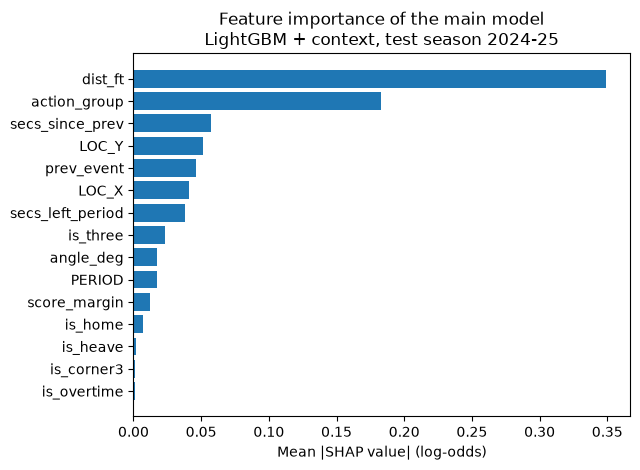

,dist_ft,action_group,secs_since_prev,LOC_Y,prev_event,LOC_X,secs_left_period,is_three,angle_deg,PERIOD,score_margin,is_home,is_heave,is_corner3,is_overtime
mean_abs_shap,0.3493,0.1825,0.0572,0.0514,0.0464,0.0407,0.0379,0.023,0.0172,0.0172,0.012,0.0069,0.0016,0.0009,0.0008


In [8]:
FEATS = GBM_FEATURES + CONTEXT_FEATURES
tr = df["SEASON"].isin(["2022-23", "2023-24"]).to_numpy()
model = GBMModel(features=FEATS).fit(df[tr], y[tr])
sample = df[df["SEASON"] == "2024-25"].sample(100_000, random_state=0)
contrib = model.model_.predict(gbm_matrix(sample, model.categories_, FEATS), pred_contrib=True)
shap = pd.DataFrame(contrib[:, :-1], columns=FEATS, index=sample.index)  # last column = base value
print(f"base value (log-odds): {contrib[0, -1]:.3f}")

importance = shap.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.barh(importance.index, importance.values)
ax.set(xlabel="Mean |SHAP value| (log-odds)", title="Feature importance of the main model\nLightGBM + context, test season 2024-25")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_shap_importance.pdf")
plt.show()
display(importance.sort_values(ascending=False).round(4).to_frame("mean_abs_shap").T)

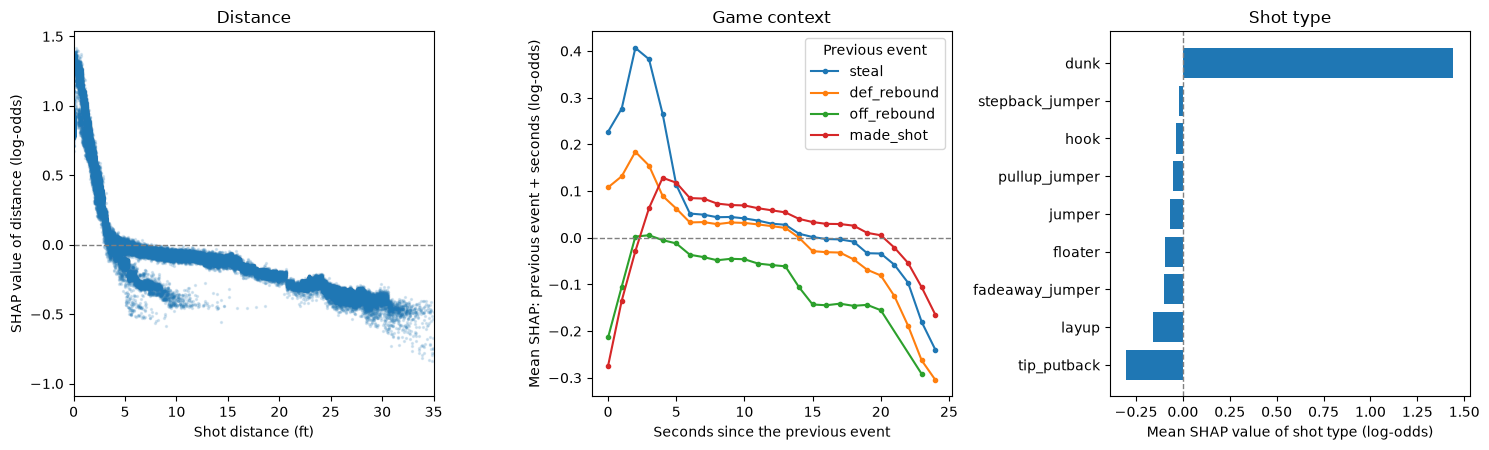

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axes[0]
ax.scatter(sample["dist_ft"], shap["dist_ft"], s=2, alpha=0.15, rasterized=True)
ax.axhline(0, color="grey", ls="--", lw=1)
ax.set(xlabel="Shot distance (ft)", ylabel="SHAP value of distance (log-odds)", xlim=(0, 35), title="Distance")

ax = axes[1]
for ev in ["steal", "def_rebound", "off_rebound", "made_shot"]:
    m = sample["prev_event"] == ev
    total = (shap.loc[m, "secs_since_prev"] + shap.loc[m, "prev_event"]).groupby(sample.loc[m, "secs_since_prev"].clip(upper=24)).mean()
    ax.plot(total.index, total.values, marker="o", ms=3, label=ev)
ax.axhline(0, color="grey", ls="--", lw=1)
ax.set(xlabel="Seconds since the previous event", ylabel="Mean SHAP: previous event + seconds (log-odds)",
       title="Game context")
ax.legend(title="Previous event")

ax = axes[2]
by_group = shap["action_group"].groupby(sample["action_group"].astype(str)).mean().sort_values()
ax.barh(by_group.index, by_group.values)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set(xlabel="Mean SHAP value of shot type (log-odds)", title="Shot type")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_shap_dependence.pdf", dpi=200)
plt.show()

**Observations.**
- **Distance** is by far the most important feature (mean |SHAP| 0.35), then **shot type** (0.18). The context features
  come next: seconds since the previous event (0.057) and the previous event (0.046), at the level of the court
  coordinates. Score margin, home court and the flags are close to zero.
- Distance: a steep drop in the first 4 ft, then an almost flat plateau up to the 3PT line and a second step behind it.
  The lower branch at 3-10 ft are shots whose distance effect depends on the shot type (interaction found by the trees).
- Context: a shot within 2-4 s after a **steal** gets +0.4 log-odds (about +10 p.p. at 50%), after a defensive rebound
  +0.15; the bonus disappears after about 6 s, when the defence is set. Late in the possession (over 20 s) the effect is
  negative for every start: forced shots at the end of the shot clock.
- Shots right after an **offensive rebound** have a *negative* contribution, although their raw FG% is high (50%):
  they are taken at the rim, and given that distance and shot type (tip, putback) they go in less often than an average
  shot from the same spot. The raw table shows the location, SHAP the effect on top of it.
- Shot type: dunks +1.4 log-odds on top of the distance; all other types differ much less from each other.
- Caveat: SHAP describes what the *model* uses, not causes. Correlated features (distance, coordinates, `is_three`)
  share their contributions, so single values should be read together.